# Preprocesamiento e ingeniería de características

## Entrega P2

Este cuaderno parte de las decisiones de calidad tomadas en P1 (cuaderno 01) y construye la tabla de descriptores por sujeto que usan los modelos del cuaderno 04.

Hay dos tipos de transformaciones. Las que no dependen de la etiqueta ni de otros sujetos (filtrado de zancadas, cálculo de descriptores) se aplican aquí, una sola vez. Las que sí aprenden algo de los datos (imputación, escalamiento) se dejan dentro del pipeline de cada modelo, para que se ajusten solo con los sujetos de entrenamiento de cada partición.

In [1]:
import subprocess
import sys
from pathlib import Path

REPOSITORIO = "https://github.com/jeraldinedione/proyecto-machine-learning.git"


def raiz_del_proyecto(inicio: Path) -> Path:
    for carpeta in [inicio, *inicio.parents]:
        if (carpeta / "src" / "gait").is_dir():
            return carpeta
    raise FileNotFoundError("No se encontró la raíz del proyecto")


if "google.colab" in sys.modules:
    if not Path("marcha").exists():
        subprocess.run(["git", "clone", "--quiet", REPOSITORIO, "marcha"], check=True)
    RAIZ = Path("marcha").resolve()
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "--quiet", "-r", str(RAIZ / "requirements.txt")],
        check=True,
    )
else:
    RAIZ = raiz_del_proyecto(Path.cwd())

sys.path.insert(0, str(RAIZ / "src"))
print(RAIZ)

/Users/nllerenas/Chiwawa/proyecto-machine-learning


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from gait import cohort, config, download, gaitndd, plots

download.fetch(config.GAITNDD)
plots.use_paper_style()
config.TABLES_DIR.mkdir(parents=True, exist_ok=True)
config.PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

---

## 1. Filtrado de zancadas

Se mantienen las tres reglas de P1: intervalo de zancada entre 0.5 y 2.5 s, apoyo doble no negativo y porcentajes de fase dentro de [0, 100]. `hunt20` se excluye siempre porque su canal derecho no registra despegues.

En P1 se dejó pendiente qué pasa si además se aplica el filtro por dispersión (mediana ± 4 MAD dentro de cada sujeto). La tabla compara los tres niveles. El filtro fisiológico es el que usan todos los modelos; los otros dos se evalúan como análisis de sensibilidad en el cuaderno 05.

In [3]:
sujetos = gaitndd.read_subject_table()
crudas = gaitndd.read_all_strides()

conteo = pd.DataFrame({
    modo: cohort.clean_strides(crudas, modo).groupby("group").size()
    for modo in cohort.FILTER_MODES
}).reindex(config.GROUP_ORDER)
conteo.loc["total"] = conteo.sum()
conteo.index = [config.GROUP_LABELS.get(g, g) for g in conteo.index]
conteo.columns = ["sin filtro", "fisiológico", "fisiológico + MAD"]
conteo

,sin filtro,fisiológico,fisiológico + MAD
Control,4076,4075,3963
Parkinson,3688,3672,3575
Huntington,4608,4585,4517
ELA,2550,2400,2353
total,14922,14732,14408


La columna "sin filtro" ya excluye a `hunt20`, por eso suma 15 024 y no 15 160.

---

## 2. Descriptores por sujeto

De cada serie filtrada se calculan 12 descriptores. Diez vienen de P1 y dos son nuevos. El balanceo medio, que estaba en P1, se descarta en la sección 4.

| Familia | Variable | Definición |
|---|---|---|
| Ritmo | `stride_mean` | duración media de la zancada izquierda (s) |
| Variabilidad | `stride_cv` | desviación estándar / media |
| | `stride_iqr` | rango intercuartílico (s) |
| | `stride_diff_cv` | raíz del cuadrado medio de las diferencias entre zancadas consecutivas, dividida por la media |
| Simetría | `asymmetry_stride` | 200·\|I − D\| / (I + D) sobre las duraciones medias |
| | `asymmetry_swing` | lo mismo sobre el porcentaje de balanceo |
| Estructura temporal | `autocorr_lag1` | autocorrelación de retardo 1 |
| | `dfa_alpha` | exponente α del *detrended fluctuation analysis* |
| | `sample_entropy` | entropía muestral con m = 2 y r = 0.2·DE |
| Fases del ciclo | `swing_pct_cv` | CV del balanceo (% del ciclo) |
| | `double_support_pct_mean`, `double_support_pct_cv` | media y CV del apoyo doble (% del ciclo) |

**Por qué los dos nuevos.** El CV mezcla dos cosas: la variación lenta a lo largo de los cinco minutos (cambios de velocidad, giros al final del pasillo) y la variación de una zancada a la siguiente. `stride_diff_cv` usa diferencias sucesivas, que eliminan las tendencias lentas y dejan solo la segunda. La entropía muestral mide qué tan predecible es la serie a escala corta; complementa a DFA, que mira correlaciones a escalas largas. Ambas medidas se usan en la literatura de variabilidad de la marcha y están verificadas en `tests/test_modeling.py` (la entropía de ruido blanco gaussiano da ≈ 2.2, el valor teórico para r = 0.2).

In [4]:
zancadas = cohort.clean_strides(crudas)
datos = cohort.subject_dataset(zancadas, sujetos)
print(f"{len(datos)} sujetos, {len(config.GAIT_FEATURES)} descriptores de marcha")
datos[["record", "group"] + config.GAIT_FEATURES].head()

63 sujetos, 12 descriptores de marcha


,record,group,stride_mean,stride_cv,stride_iqr,stride_diff_cv,asymmetry_stride,autocorr_lag1,dfa_alpha,sample_entropy,swing_pct_cv,double_support_pct_mean,double_support_pct_cv,asymmetry_swing
0,als1,als,1.276,0.087,0.113,0.098,0.046,0.373,0.852,1.636,0.060,35.877,0.107,8.651
1,als10,als,1.134,0.030,0.039,0.032,0.006,0.426,0.905,1.627,0.023,34.935,0.041,0.197
2,als11,als,1.215,0.051,0.040,0.061,0.001,0.275,0.786,1.322,0.043,33.404,0.086,3.598
3,als12,als,1.404,0.076,0.080,0.065,0.083,0.629,1.030,1.443,0.077,34.590,0.148,6.482
4,als13,als,1.520,0.061,0.092,0.058,0.006,0.539,1.001,1.516,0.060,35.802,0.099,3.857


---

## 3. Variables que quedan fuera del modelo

| Variable | Motivo |
|---|---|
| `n_strides` | depende del filtrado, que descarta más zancadas en ELA y Huntington que en controles; además es casi la inversa de `stride_mean` |
| `observed_span_s` | tiempo entre la primera y la última zancada válida; es un artefacto del protocolo y del filtrado |
| `cadence_strides_per_min` | se calcula a partir de `n_strides` |
| `stride_sd` | es `stride_cv` × `stride_mean` |
| `swing_pct_mean` | en cada zancada el apoyo doble es lo que queda del ciclo tras los dos balanceos, así que su media es función lineal del balanceo medio (sección 4) |
| `*_sd`, `*_iqr` de las fases | redundantes con el CV de la misma fase |
| `height_m`, `weight_kg` | cada subcohorte usa una convención de unidades distinta (P1, sección 6) |
| severidad y sus tres columnas derivadas | cada escala existe solo en un grupo: fuga directa de la etiqueta. Se usan en el análisis de errores |
| `age`, `male`, `speed_ms` | no entran al modelo principal; se usan para medir el efecto de los confusores |

Las redundancias por construcción se comprueban con los datos.

In [5]:
redundancia = pd.Series({
    "n_strides ~ stride_mean": datos.n_strides.corr(datos.stride_mean),
    "cadence ~ stride_mean": datos.cadence_strides_per_min.corr(datos.stride_mean),
    "stride_sd ~ stride_cv": datos.stride_sd.corr(datos.stride_cv),
    "swing_pct_mean ~ double_support_pct_mean": datos.swing_pct_mean.corr(datos.double_support_pct_mean),
}, name="r de Pearson")
redundancia.round(3)

n_strides ~ stride_mean                    -0.893
cadence ~ stride_mean                      -0.937
stride_sd ~ stride_cv                       0.958
swing_pct_mean ~ double_support_pct_mean   -1.000
Name: r de Pearson, dtype: float64

In [6]:
por_sujeto = pd.DataFrame({
    "zancadas crudas": cohort.clean_strides(crudas, "none").groupby(["group", "record"]).size().groupby("group").mean(),
    "zancadas válidas": datos.groupby("group").n_strides.mean(),
}).reindex(config.GROUP_ORDER)
por_sujeto["% descartado"] = 100 * (1 - por_sujeto["zancadas válidas"] / por_sujeto["zancadas crudas"])
por_sujeto.index = plots.labels_for(config.GROUP_ORDER)
por_sujeto.round(1)

,zancadas crudas,zancadas válidas,% descartado
Control,254.800,254.700,0.000
Parkinson,245.900,244.800,0.400
Huntington,242.500,241.300,0.500
ELA,196.200,184.600,5.900


El número de zancadas válidas por sujeto lleva información de la clase por dos vías que no son la marcha en sí: los pacientes caminan más lento (menos zancadas en el mismo tiempo) y el filtro les descarta más. Un modelo que lo use estaría aprendiendo, en parte, cuántos errores de detección tuvo el sensor.

---

## 4. Redundancia entre los descriptores retenidos

La primera versión de esta matriz incluía el balanceo medio, que daba r = −1.00 con el apoyo doble medio. No es una casualidad de esta muestra: en cada zancada, apoyo doble ≈ 100 − balanceo izquierdo − balanceo derecho (en % del ciclo). Sobra una de las dos y se conserva el apoyo doble, que tiene una lectura clínica directa como estrategia de estabilidad. La matriz siguiente ya no incluye el balanceo medio.

In [7]:
correlacion = datos[config.GAIT_FEATURES].corr()
superior = correlacion.where(np.triu(np.ones(correlacion.shape, dtype=bool), k=1)).stack()
superior[superior.abs() > 0.7].sort_values(key=np.abs, ascending=False).round(2).to_frame("r")

r
stride_cv      stride_diff_cv        0.960
stride_diff_cv swing_pct_cv          0.870
autocorr_lag1  dfa_alpha             0.860
stride_cv      stride_iqr            0.860
               swing_pct_cv          0.850
stride_iqr     swing_pct_cv          0.830
               stride_diff_cv        0.820
swing_pct_cv   double_support_pct_cv 0.810
stride_cv      double_support_pct_cv 0.780
stride_diff_cv double_support_pct_cv 0.760

Quedan pares muy correlacionados: las medidas de variabilidad entre sí (CV, IQR, variabilidad sucesiva y CV de las fases) y la autocorrelación con DFA. Con 63 sujetos, eliminar variables a mano mirando esta matriz sería otra decisión tomada con todos los datos, incluidos los que después se usan para evaluar. Preferimos que la redundancia la maneje cada modelo: la regresión logística con penalización L1/L2 ajustada en la validación interna, y el bosque con el submuestreo de variables en cada división.

La correlación sí afecta la interpretación: la importancia por permutación de una variable se reparte con las que están correlacionadas con ella. Se tiene en cuenta en el cuaderno 05.

---

## 5. Valores faltantes y escalamiento

In [8]:
candidatas = config.GAIT_FEATURES + config.DEMOGRAPHIC_FEATURES + config.SPEED_FEATURES
faltantes = datos[candidatas].isna().sum()
print(faltantes[faltantes > 0].to_string())
print()
print(datos.loc[datos.speed_ms.isna(), ["record", "group", "age", "sex"]].to_string(index=False))

speed_ms    2

record group  age sex
  als4   als   70   f
  als5   als   36   m


Ningún descriptor de marcha tiene faltantes a nivel de sujeto. Solo falta la velocidad de dos sujetos con ELA (la de `hunt20` también faltaba, pero ese sujeto ya está excluido). Se imputa con la mediana del conjunto de entrenamiento, dentro del pipeline (`SimpleImputer`), y solo afecta a los experimentos que usan la velocidad.

El escalamiento (`StandardScaler`) también vive dentro del pipeline. Si se estandarizara aquí con los 63 sujetos, la media y la desviación de los sujetos de prueba entrarían al entrenamiento. Los modelos de árboles no se escalan.

---

## 6. Descriptores por grupo

La tabla resume la media de cada descriptor por grupo y la prueba de Kruskal-Wallis entre los cuatro grupos. Es descriptiva: no hay corrección por comparaciones múltiples y no reemplaza la evaluación fuera de muestra.

In [9]:
medias = datos.groupby("group")[config.GAIT_FEATURES].mean().reindex(config.GROUP_ORDER).T
medias.columns = plots.labels_for(config.GROUP_ORDER)
medias["p (Kruskal-Wallis)"] = [
    stats.kruskal(*[datos.loc[datos.group == g, f] for g in config.GROUP_ORDER]).pvalue
    for f in config.GAIT_FEATURES
]
medias.index = [config.FEATURE_LABELS[f] for f in medias.index]
medias.to_csv(config.TABLES_DIR / "descriptores_por_grupo.csv")
medias.style.format("{:.3f}").format("{:.1e}", subset="p (Kruskal-Wallis)")

,Control,Parkinson,Huntington,ELA,p (Kruskal-Wallis)
duración media,1.097,1.125,1.152,1.356,2.3e-04
CV de zancada,0.041,0.074,0.105,0.063,5.7e-06
IQR de zancada,0.037,0.070,0.134,0.088,3.3e-06
variab. sucesiva,0.042,0.082,0.136,0.064,3.8e-07
asimetría de zancada,0.035,0.157,0.258,0.114,1.1e-01
autocorrelación,0.486,0.322,0.190,0.434,1.1e-03
DFA α,0.875,0.805,0.653,0.850,1.0e-04
entropía muestral,1.458,1.445,1.731,1.613,5.7e-02
CV de balanceo,0.029,0.067,0.087,0.054,1.2e-06
apoyo doble medio,28.213,34.030,31.975,35.318,6.3e-04


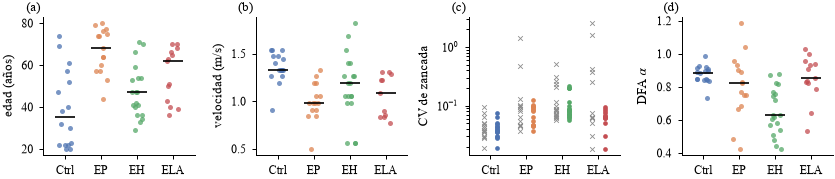

In [10]:
sin_filtro = cohort.subject_dataset(cohort.clean_strides(crudas, "none"), sujetos)

fig, axes = plt.subplots(1, 4, figsize=(plots.PAGE_WIDTH, 1.7))

plots.group_points(axes[0], datos, "age")
axes[0].set_ylabel("edad (años)")

plots.group_points(axes[1], datos, "speed_ms")
axes[1].set_ylabel("velocidad (m/s)")

for posicion, grupo in enumerate(config.GROUP_ORDER):
    antes = sin_filtro.loc[sin_filtro.group == grupo, "stride_cv"]
    despues = datos.loc[datos.group == grupo, "stride_cv"]
    axes[2].scatter(np.full(len(antes), posicion - 0.18), antes, s=8, marker="x", color="0.55", lw=0.5)
    axes[2].scatter(np.full(len(despues), posicion + 0.18), despues, s=8, color=config.GROUP_COLORS[grupo], lw=0)
axes[2].set_yscale("log")
axes[2].set_xticks(range(4), plots.short_labels_for(config.GROUP_ORDER))
axes[2].set_xlim(-0.6, 3.6)
axes[2].set_ylabel("CV de zancada")

plots.group_points(axes[3], datos, "dfa_alpha")
axes[3].set_ylabel(r"DFA $\alpha$")

for ax, letra in zip(axes, "abcd"):
    plots.panel_label(ax, f"({letra})")
fig.tight_layout(w_pad=0.8)
plots.save(fig, "eda_resumen")

---

## 7. Representación por ventanas

El segundo enfoque de modelado (cuaderno 04) entrena con ventanas de 30 zancadas consecutivas y luego promedia las probabilidades de las ventanas de cada sujeto. Las ventanas multiplican las filas de entrenamiento, pero la partición y la evaluación siguen siendo por sujeto.

In [11]:
ventanas = cohort.window_dataset(zancadas, sujetos, window_strides=30)
print(f"{len(ventanas)} ventanas de {ventanas.record.nunique()} sujetos")
print(ventanas.groupby("group").size().reindex(config.GROUP_ORDER).rename(index=config.GROUP_LABELS).to_string())
print()
indefinidos = ventanas[config.GAIT_FEATURES].isna().mean()
print("proporción de ventanas con descriptor indefinido:")
print(indefinidos[indefinidos > 0].round(3).to_string())

480 ventanas de 63 sujetos
group
Control       132
Parkinson     119
Huntington    150
ELA            79

proporción de ventanas con descriptor indefinido:
sample_entropy   0.406


La entropía muestral no está definida en una fracción grande de las ventanas: con 30 puntos a veces no hay ningún par de plantillas de longitud 3 que coincida. Imputar ese valor en cuatro de cada diez ventanas sería inventar la variable, así que el enfoque por ventanas usa los otros 11 descriptores. DFA en 30 zancadas usa cajas de 4 a 7 puntos y es una estimación pobre; se mantiene, pero su importancia en ese enfoque debe leerse con cuidado.

In [12]:
datos.to_csv(config.PROCESSED_DIR / "descriptores_sujeto.csv", index=False)
ventanas.to_csv(config.PROCESSED_DIR / "descriptores_ventana.csv", index=False)

---

## Resumen de decisiones

1. Filtro fisiológico de P1 y exclusión de `hunt20`: 63 sujetos y 14 732 zancadas.
2. Doce descriptores de marcha por sujeto: diez de P1 más variabilidad sucesiva y entropía muestral. El balanceo medio se descarta por ser función lineal del apoyo doble.
3. Fuera del modelo: conteos de zancadas, variables redundantes por construcción, antropometría con unidades inconsistentes y la columna de severidad.
4. Edad, sexo y velocidad se reservan para el análisis de confusores.
5. Imputación y escalamiento dentro del pipeline, ajustados solo con los sujetos de entrenamiento.
6. Para el enfoque por ventanas: 30 zancadas y 11 descriptores (sin entropía muestral).